In [2]:
from rdkit import Chem
import pickle
import os
import json
import joblib

In [3]:
reactions_dir = "reactions"
reaction_id = 15
reaction_dir = os.path.join(reactions_dir, str(reaction_id))
mol_objects = []

for root, dirs, files in os.walk(reaction_dir):
    files.sort()
    for file in files:
        if file.endswith(".pkl"):
            file_path = os.path.join(root, file)
            with open(file_path, "rb") as f:
                try:
                    mol = pickle.load(f)
                    if mol:
                        mol_objects.append(mol)
                except Exception as e:
                    print(f"Error processing {file_path}: {e}")

print(f"Converted {len(mol_objects)} pickle files to RDKit Mol objects.")

Converted 27 pickle files to RDKit Mol objects.


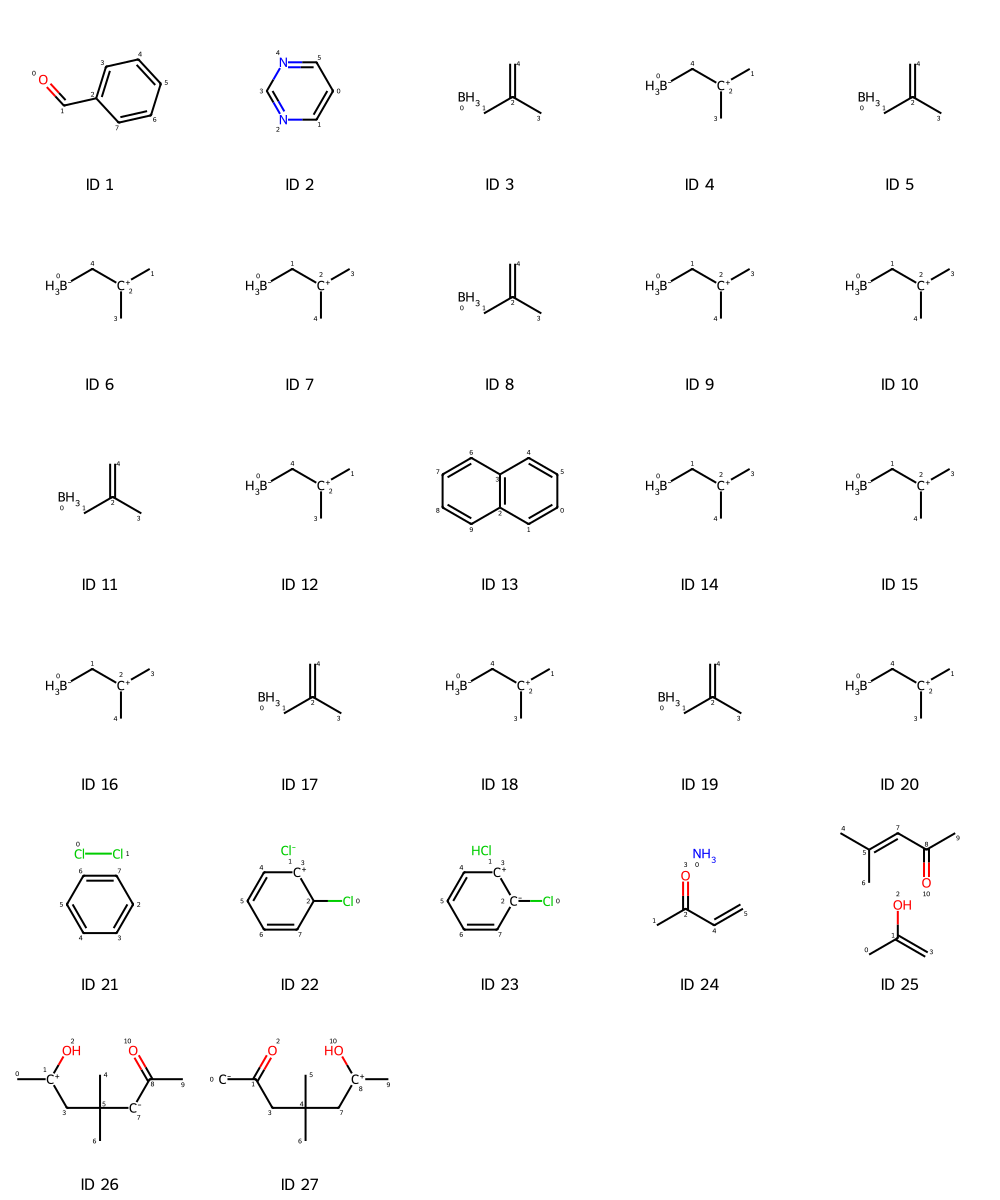

In [4]:
opt = Chem.Draw.MolDrawOptions()
opt.addAtomIndices = True
Chem.Draw.MolsToGridImage(mol_objects, molsPerRow=5, subImgSize=(200, 200), legends=[f"ID {i+1}" for i in range(len(mol_objects))], drawOptions=opt)

In [5]:
training_id = 6
training_dir = os.path.join("training", str(training_id))
t_mol_objects = []

for root, dirs, files in os.walk(training_dir):
    files.sort()
    for file in files:
        if file.endswith(".pkl"):
            file_path = os.path.join(root, file)
            with open(file_path, "rb") as f:
                try:
                    mol = pickle.load(f)
                    if mol:
                        if file == "sm.pkl":
                            sm = mol
                        else:
                            t_mol_objects.append(mol)
                except Exception as e:
                    print(f"Error processing {file_path}: {e}")
    
with open(os.path.join(training_dir,'data.json'), 'r') as file:
    data = json.load(file)

t_mol_objects = [sm] + t_mol_objects

print(f"Converted {len(t_mol_objects)} pickle files to RDKit Mol objects.")
print(data)

Converted 6 pickle files to RDKit Mol objects.
{'choices': {'0': {'mechanism': [1, 0, 2, None, 3], 'probable': 0}, '1': {'mechanism': [3, 2, 0, 3, 1], 'probable': 1}, '2': {'mechanism': [3, 2, 4, 3, 5], 'probable': 0}, '3': {'mechanism': [3, 3, 4, 2, 5], 'probable': 0}, '4': {'mechanism': [3, 2, 5, 3, 4], 'probable': 0}}}


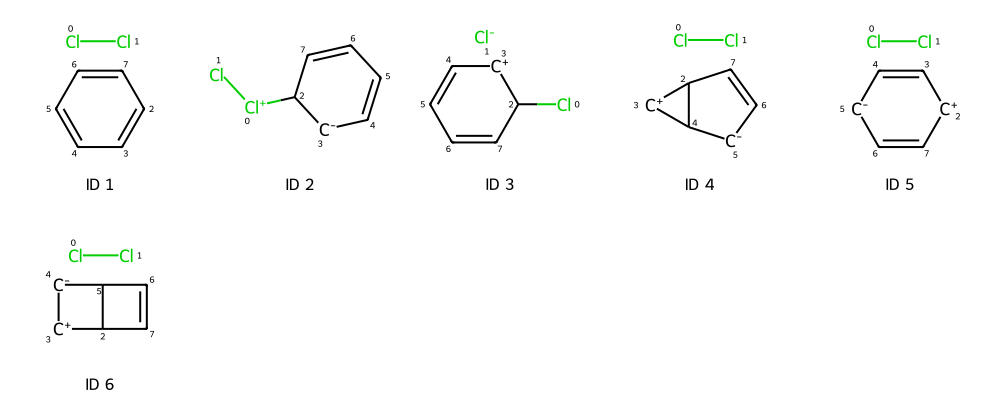

In [6]:
Chem.Draw.MolsToGridImage(t_mol_objects, molsPerRow=5, subImgSize=(200, 200), legends=[f"ID {i+1}" for i in range(len(t_mol_objects))], drawOptions=opt)

In [7]:
# Data analysis

arrow_types = {
    0: "atom to atom",
    1: "atom to bond",
    2: "bond to atom",
    3: "bond to bond",
    4: "atom to H+",
    5: "bond to H+",
    6: "H- to atom",
    7: "H- to bond",
}

bitvectors = []
outcomes = []


choices = data['choices']
for id, info in choices.items():
    print(arrow_types[info['mechanism'][0]])
    if info['mechanism'][0] < 4:
        a1 = make_atom_fingerprint(t_mol_objects[0].GetAtomWithIdx(info['mechanism'][1]))
        a2 = make_atom_fingerprint(t_mol_objects[0].GetAtomWithIdx(info['mechanism'][2]))
        sum_finger_print = [info['mechanism'][1]] + a1 + a2
        bitvectors.append(sum_finger_print)
        outcomes.append(info['probable'])

atom to bond


NameError: name 'make_atom_fingerprint' is not defined

In [8]:
def make_atom_fingerprint(atom):

    # Charge bitstring
    charge_bitstring = [0] * 3
    if atom.GetFormalCharge() < 0:
        charge_bitstring[0] = 1
    elif atom.GetFormalCharge() == 0:
        charge_bitstring[1] = 1
    elif atom.GetFormalCharge() > 0:
        charge_bitstring[2] = 1

    # H bitstring
    h_number_bitstring = [0] * 4
    if atom.GetTotalNumHs() == 0:
        h_number_bitstring[0] = 1
    elif atom.GetTotalNumHs() == 1:
        h_number_bitstring[1] = 1
    elif atom.GetTotalNumHs() == 2:
        h_number_bitstring[2] = 1
    elif atom.GetTotalNumHs() > 2:
        h_number_bitstring[3] = 1

    # Hybridization bitstring
    hybridization_bitstring = [0] * 3
    if atom.GetHybridization() == Chem.rdchem.HybridizationType.SP:
        hybridization_bitstring[0] = 1
    elif atom.GetHybridization() == Chem.rdchem.HybridizationType.SP2:
        hybridization_bitstring[1] = 1
    elif atom.GetHybridization() == Chem.rdchem.HybridizationType.SP3:
        hybridization_bitstring[2] = 1

    # Element bitstring
    # [AlkMet, B, C, N, O, F, Mg, Al, Si, P, S, Cl, Br, I, Met]
    ptable = Chem.GetPeriodicTable()
    element_bitstring = [0] * 15
    dict_elements = { 5: 1,
                      6: 2,
                      7: 3,
                      8: 4,
                      9: 5,
                      12: 6,
                      13: 7,
                      14: 8,
                      15: 9,
                      16: 10,
                      17: 11,
                      35: 12,
                      53: 13}
    atm_num = atom.GetAtomicNum()
    if atm_num in dict_elements:
        element_bitstring[dict_elements[atm_num]] = 1
    elif ptable.GetNOuterElecs(atm_num) == 1:
        element_bitstring[0] = 1
    elif atm_num <= 30 and atm_num >= 20:
        element_bitstring[14] = 1

    # TODO: aromaticity bitstring

    # adjacency bitstring
    # [C+, C-, CH0, CH, C-EN, C=EN, EN, EP]

    total_bit_string = charge_bitstring + h_number_bitstring + hybridization_bitstring + element_bitstring
    return total_bit_string

   




In [9]:
# Data analysis

arrow_types = {
    0: "atom to atom",
    1: "atom to bond",
    2: "bond to atom",
    3: "bond to bond",
    4: "atom to H+",
    5: "bond to H+",
    6: "H- to atom",
    7: "H- to bond",
}


training_dir = "training"


# Get list of subdirectories and sort them numerically
subdirs = [d for d in os.listdir(training_dir) if os.path.isdir(os.path.join(training_dir, d))]
subdirs = sorted(subdirs, key=lambda x: int(x))  # Sort by integer folder name

bitvectors = []
outcomes = []

for subdir in subdirs:
    folder_path = os.path.join(training_dir, subdir)
    json_path = os.path.join(folder_path, 'data.json')
    pkl_path = os.path.join(folder_path, 'sm.pkl')
    with open(pkl_path, "rb") as f:
        try:
            sm = pickle.load(f)
        except Exception as e:
                    print(f"Error processing {file_path}: {e}")
    with open(json_path, 'r') as file:
        data = json.load(file)
    choices = data['choices']
    for id, info in choices.items():
        #print(arrow_types[info['mechanism'][0]])
        if info['mechanism'][0] < 4:
            a1 = make_atom_fingerprint(sm.GetAtomWithIdx(info['mechanism'][1]))
            a2 = make_atom_fingerprint(sm.GetAtomWithIdx(info['mechanism'][2]))
            sum_finger_print = [info['mechanism'][0]] + a1 + a2
            bitvectors.append(sum_finger_print)
            outcomes.append(info['probable'])



In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [14]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)

# Logistic Regression classifier
clf = LogisticRegression()
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
joblib.dump(clf, 'model.pkl')

Accuracy: 0.9591836734693877


['model.pkl']